[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_qnionsrot.ipynb)


# Quaternions and rotations

Quaternions extend complex numbers and combine a scalar with a three-dimensional vector to form a four-dimensional object:

$$
\mathbf{q}=a+x \mathbf{i}+y \mathbf{j}+z \mathbf{k}\mathbf{  }\mathbf{=}\mathbf{ }\left\{a\mathbf{,}\mathbf{ }\mathbf{v}\right\}, \\ a,x,y,z \in  R\\ {\mathbf{i}}^{2}={\mathbf{j}}^{2}={\mathbf{k}}^{2}=-1\\ \mathbf{i}*\mathbf{j}\mathbf{=} -\mathbf{j}\mathbf{*}\mathbf{i}=\mathbf{k} + \text{cycle}\\ {\mathbf{q}}_{1}*{\mathbf{q}}_{2}=\left\{{a}_{1}{a}_{2}-{\mathbf{v}}_{1}\cdot {\mathbf{v}}_{2}, {a}_{1}{\mathbf{v}}_{2}+{a}_{2}{\mathbf{v}}_{1}+{\mathbf{v}}_{1}\times {\mathbf{v}}_{2}\right\}
$$



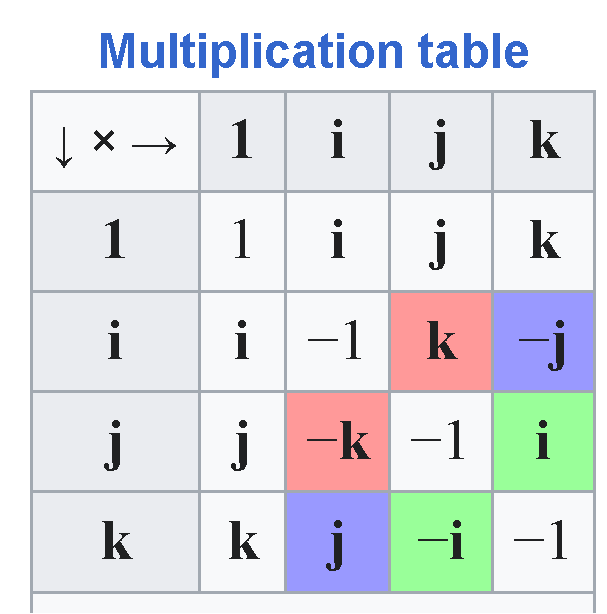


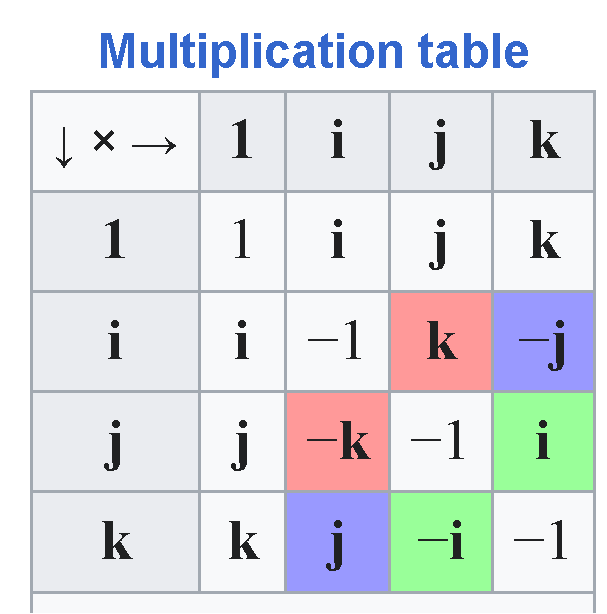

Conjugation and the norm have analogous definitions:

$$
\mathbf{\overline{\mathbf{q}}}=a-x \mathbf{i}\mathbf{-}y \mathbf{j}\mathbf{-}z \mathbf{k}\mathbf{  }\mathbf{=}\mathbf{ }\left\{a\mathbf{,}\mathbf{-v}\right\}
$$

$$
\mathbf{q*\overline{\mathbf{q}}}\mathbf{ }\mathbf{=}\mathbf{ }\mathbf{\overline{\mathbf{q}}*q}=\left|\mathbf{q}\right|^{2}\\ \overline{{\mathbf{q}}_{1}*{\mathbf{q}}_{2}}=\overline{{\mathbf{q}}_{2}} *\overline{{\mathbf{q}}_{1}}
$$

The last identity suggests a matrix representation using a pair of complex numbers (four real components):

$$
q =\left\{{x}_{0},\left\{{x}_{1},{x}_{2},{x}_{3}\right\}\right\}\to  Q\left(q\right)= \left(\begin{matrix}{x}_{0}+i {x}_{1}\\ -{x}_{2}+i {x}_{3}\end{matrix}\begin{matrix}{x}_{2}+i {x}_{3}\\ {x}_{0}-i {x}_{1}\end{matrix}\right)
$$

In [1]:
import sympy as sp
from IPython.display import display
x0,x1,x2,x3,y0,y1,y2,y3,phi=sp.symbols('x0 x1 x2 x3 y0 y1 y2 y3 varphi',real=True)
q1v=(x0,sp.Matrix([x1,x2,x3])); q2v=(y0,sp.Matrix([y1,y2,y3]))
def conj(q): return (q[0],-q[1])
def normqsq(q): return q[0]**2+q[1].dot(q[1])
def inv(q):
    s,v=conj(q); return (s/normqsq(q),v/normqsq(q))
def prodquat(p,q):
    return (sp.expand(p[0]*q[0]-p[1].dot(q[1])),p[0]*q[1]+q[0]*p[1]+p[1].cross(q[1]))
def rotate(q,v): return sp.simplify(prodquat(prodquat(q,(0,sp.Matrix(v))),inv(q))[1])
display(conj(q1v),prodquat(q1v,q2v))

(x0,
 Matrix([
 [-x1],
 [-x2],
 [-x3]]))

(x0*y0 - x1*y1 - x2*y2 - x3*y3,
 Matrix([
 [x0*y1 + x1*y0 + x2*y3 - x3*y2],
 [x0*y2 - x1*y3 + x2*y0 + x3*y1],
 [x0*y3 + x1*y2 - x2*y1 + x3*y0]]))

In [2]:
def quaternion_matrix(q):
    s=q[0]; a,b,c=q[1]
    return sp.Matrix([[s+sp.I*a,b+sp.I*c],[-b+sp.I*c,s-sp.I*a]])
q1mtrx=quaternion_matrix(q1v)
# Preserve the printed source matrix, including its x0/y0 typo.
q2mtrx_source=sp.Matrix([[y0+sp.I*y1,y2+sp.I*y3],[-y2+sp.I*y3,x0-sp.I*y1]])
q2mtrx=quaternion_matrix(q2v)
q1conj=q1mtrx.H
display(q1mtrx,q1conj,sp.simplify(q1conj*q1mtrx))
assert sp.simplify(q1conj*q1mtrx-normqsq(q1v)*sp.eye(2))==sp.zeros(2)

Matrix([
[ x0 + I*x1, x2 + I*x3],
[-x2 + I*x3, x0 - I*x1]])

Matrix([
[x0 - I*x1, -x2 - I*x3],
[x2 - I*x3,  x0 + I*x1]])

Matrix([
[x0**2 + x1**2 + x2**2 + x3**2,                             0],
[                            0, x0**2 + x1**2 + x2**2 + x3**2]])

In [3]:
display(sp.expand(q1mtrx*q2mtrx_source))
# The corrected quaternion matrix product is shown separately.
display(sp.expand(q1mtrx*q2mtrx))
s,v=prodquat(q1v,q2v)
assert sp.simplify(q1mtrx*q2mtrx-quaternion_matrix((s,v)))==sp.zeros(2)

Matrix([
[ x0*y0 + I*x0*y1 + I*x1*y0 - x1*y1 - x2*y2 + I*x2*y3 - I*x3*y2 - x3*y3, x0*x2 + I*x0*x3 + x0*y2 + I*x0*y3 + I*x1*y2 - x1*y3 - I*x2*y1 + x3*y1],
[-x0*y2 + I*x0*y3 + I*x1*y2 + x1*y3 - x2*y0 - I*x2*y1 + I*x3*y0 - x3*y1, x0**2 - I*x0*x1 - I*x0*y1 - x1*y1 - x2*y2 - I*x2*y3 + I*x3*y2 - x3*y3]])

Matrix([
[ x0*y0 + I*x0*y1 + I*x1*y0 - x1*y1 - x2*y2 + I*x2*y3 - I*x3*y2 - x3*y3, x0*y2 + I*x0*y3 + I*x1*y2 - x1*y3 + x2*y0 - I*x2*y1 + I*x3*y0 + x3*y1],
[-x0*y2 + I*x0*y3 + I*x1*y2 + x1*y3 - x2*y0 - I*x2*y1 + I*x3*y0 - x3*y1, x0*y0 - I*x0*y1 - I*x1*y0 - x1*y1 - x2*y2 - I*x2*y3 + I*x3*y2 - x3*y3]])

Quaternions form a noncommutative but associative division algebra. Thus, for a nonzero coefficient, the equation below has a unique solution:

$$
{\mathbf{q}}_{1}\mathbf{ }\mathbf{x}\mathbf{ }\mathbf{=}{\mathbf{q}}_{2} \Rightarrow  \mathbf{x} ={\mathbf{q}}_{1}^{-1}{\mathbf{q}}_{2}\\ {\mathbf{q}}^{-1}=\frac{\overline{\mathbf{q}}}{\left|\mathbf{q}\right|^{2}}
$$

## Quaternions as rotations

Naturally the “imaginary” quaternions 

$$
\mathbf{v} =x \mathbf{i}+y \mathbf{j}+z \mathbf{k}\mathbf{ }\mathbf{=}\mathbf{ }\mathbf{-\overline{v}}
$$

can be identified with vectors in $\mathbb{R}^3$. Conjugation by a nonzero quaternion, which may be normalized to unit norm,

$$
\mathbf{v} \to \mathbf{w}\mathbf{ }\mathbf{=} \mathbf{q}\mathbf{ }\mathbf{*}\mathbf{v}\mathbf{*}\mathbf{ }{\mathbf{q}}^{-1}: \overline{\mathbf{w}} = -\mathbf{w}
$$

defines a rotation of $\mathbb{R}^3$. The quaternions $q$ and $-q$ define the same rotation, giving a two-to-one correspondence between unit quaternions and rotation matrices.

In [4]:
basis=[sp.eye(3)[:,j] for j in range(3)]
rotation_matrix=sp.Matrix.hstack(*(rotate(q1v,v) for v in basis))
# The source displays the numerator under the assumption |q|=1.
rotation_matrix_unit=sp.simplify(normqsq(q1v)*rotation_matrix)
display(rotation_matrix_unit)

Matrix([
[x0**2 + x1**2 - x2**2 - x3**2,            -2*x0*x3 + 2*x1*x2,             2*x0*x2 + 2*x1*x3],
[            2*x0*x3 + 2*x1*x2, x0**2 - x1**2 + x2**2 - x3**2,            -2*x0*x1 + 2*x2*x3],
[           -2*x0*x2 + 2*x1*x3,             2*x0*x1 + 2*x2*x3, x0**2 - x1**2 - x2**2 + x3**2]])

The rotation axis is parallel to $\operatorname{Im}\left(q\right)$ when this vector is nonzero.

In [5]:
rotated_axis=rotate(q1v,q1v[1])
display(rotated_axis)
assert sp.simplify(rotated_axis-q1v[1])==sp.zeros(3,1)

Matrix([
[x1],
[x2],
[x3]])

For a quaternion aligned with the z axis, the rotation angle is illustrated by:

In [6]:
qz=(sp.cos(phi/2),sp.Matrix([0,0,sp.sin(phi/2)]))
rotated=prodquat(prodquat(qz,(0,sp.Matrix([x1,x2,0]))),inv(qz))
display((sp.simplify(rotated[0]),sp.trigsimp(rotated[1])))

(0,
 Matrix([
 [x1*cos(varphi) - x2*sin(varphi)],
 [x1*sin(varphi) + x2*cos(varphi)],
 [                              0]]))

Thus ${q}_{1}{q}_{2}$ corresponds to $R\left({q}_{1}\right)R\left({q}_{2}\right)$

[Back to the course contents](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)